In [131]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

In [132]:
X, y = fetch_openml(data_id=41082, as_frame=False, return_X_y=True)

In [133]:
X = MinMaxScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=8)

In [134]:
r = np.random.RandomState(8)

noise = r.normal(scale=0.75, size=X_train.shape)
X_train_noised = X_train + noise

noise = r.normal(scale=0.75, size=X_test.shape)
X_test_noised = X_test + noise

In [135]:
pca = PCA(n_components=10, random_state=8)

X_train_pca = pca.fit_transform(X_train)
X_test_pca  = pca.transform(X_test)

## Задание 1

### Логистическая регрессия

In [136]:
log_clf = LogisticRegression(max_iter=3000, random_state=8)
log_clf.fit(X_train, y_train)
y_pred = log_clf.predict(X_test)
score_log_noisy = accuracy_score(y_pred, y_test)

log_pca = LogisticRegression(max_iter=3000, random_state=8)
log_pca.fit(X_train_pca, y_train)
y_pred_pca = log_pca.predict(X_test_pca)
score_log_pca = accuracy_score(y_pred_pca, y_test)


In [137]:
print(f"Log noisy score = {score_log_noisy} \nLog PCA score = {score_log_pca}")

Log noisy score = 0.9489247311827957 
Log PCA score = 0.8838709677419355


Для логистической регрессии снижение размерности ухудшило качество (для n = 10).
Это означает, что в данном датасете даже шумные исходные признаки содержат важную информацию, которую PCA частично "обрезал". Модель логистической регрессии способна эффективно работать в исходном пространстве признаков.
Если брать большее число главных компонент, то результат сопоставим с зашумленным

### SVM

In [138]:
svm_clf = LinearSVC(max_iter=3000, random_state=8)
svm_clf.fit(X_train, y_train)
y_pred = svm_clf.predict(X_test)
score_svm_noisy = accuracy_score(y_pred, y_test)

svm_pca = LinearSVC(max_iter=3000, random_state=8)
svm_pca.fit(X_train_pca, y_train)
y_pred_pca = svm_pca.predict(X_test_pca)
score_svm_pca = accuracy_score(y_pred_pca, y_test)

In [139]:
print(f"SVM noisy score = {score_svm_noisy} \nSVM PCA score = {score_svm_pca}")

SVM noisy score = 0.9435483870967742 
SVM PCA score = 0.8580645161290322


Аналогично логистической регрессии, для Linear SVM точность после PCA заметно снизилась (для n = 10).
Поскольку шум был добавлен одинаково по всем признакам, PCA не смог достаточно выделить структурные компоненты, и часть полезной информации о цифрах была потеряна.
Если брать n = 100, то результат превосходит зашумленный

## Задание 2
Динамика score при разных n_components

In [140]:
results_log = []
results_svm = []
components_list = range(10, 101)

for k in components_list:
    pca = PCA(n_components=k, random_state=8)
    X_tr = pca.fit_transform(X_train[:1000])
    X_te = pca.transform(X_test[:200])

    log_clf = LogisticRegression(max_iter=3000, random_state=8)
    log_clf.fit(X_tr, y_train[:1000])
    results_log.append(accuracy_score(log_clf.predict(X_te), y_test[:200]))

    svm_clf = LinearSVC(max_iter=3000, random_state=8)
    svm_clf.fit(X_tr, y_train[:1000])
    results_svm.append(accuracy_score(svm_clf.predict(X_te), y_test[:200]))

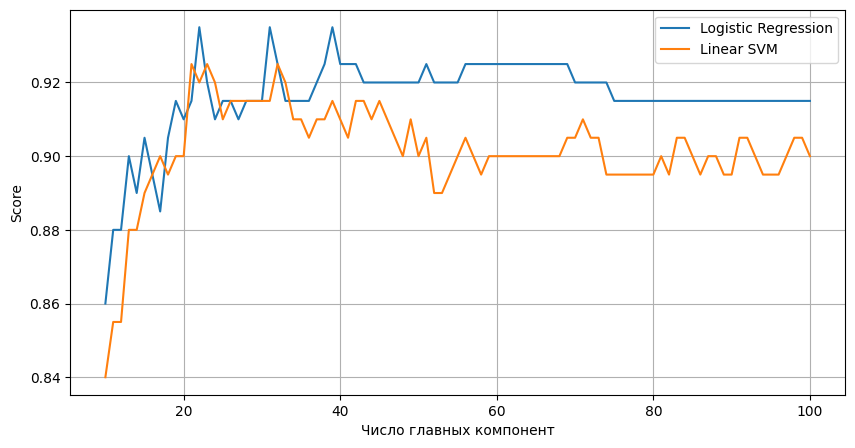

In [141]:
plt.figure(figsize=(10,5))
plt.plot(components_list, results_log, label="Logistic Regression")
plt.plot(components_list, results_svm, label="Linear SVM")
plt.xlabel("Число главных компонент")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

Оптимальный диапазон числа компонент для обеих моделей — 20–40.
Дальнейшее увеличение размерности пространства после PCA не улучшает качество и иногда даже ухудшает его из-за включения шумовых компонент.

## Задание 3

Зависимость точности от размера обучающей выборки



In [142]:
train_sizes = range(500, y.shape[0], y.shape[0] // 7)
components = [20, 40, 60]

results_log = {k: [] for k in components}
results_svm = {k: [] for k in components}

for size in train_sizes:
    X_tr_small = X_train[:size]
    y_tr_small = y_train[:size]

    for k in components:
        pca = PCA(n_components=k, random_state=8)
        X_tr_p = pca.fit_transform(X_tr_small)
        X_te_p = pca.transform(X_test)

        log_clf = LogisticRegression(max_iter=3000, random_state=8)
        log_clf.fit(X_tr_p, y_tr_small)
        pred_log = log_clf.predict(X_te_p)
        acc_log = accuracy_score(y_test, pred_log)
        results_log[k].append(acc_log)

        svm_clf = LinearSVC(max_iter=3000, random_state=8)
        svm_clf.fit(X_tr_p, y_tr_small)
        pred_svm = svm_clf.predict(X_te_p)
        acc_svm = accuracy_score(y_test, pred_svm)
        results_svm[k].append(acc_svm)


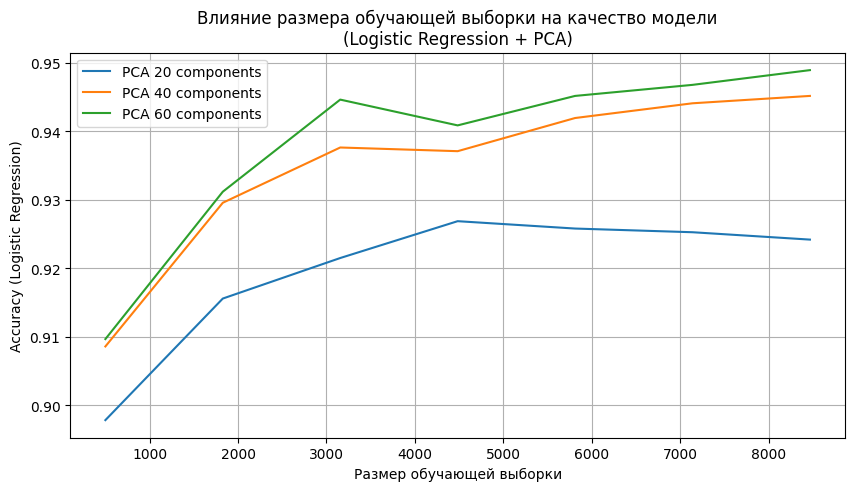

In [143]:
plt.figure(figsize=(10, 5))
for k in components:
    plt.plot(list(train_sizes), results_log[k], label=f"PCA {k} components")

plt.xlabel("Размер обучающей выборки")
plt.ylabel("Accuracy (Logistic Regression)")
plt.title("Влияние размера обучающей выборки на качество модели\n(Logistic Regression + PCA)")
plt.grid(True)
plt.legend()
plt.show()


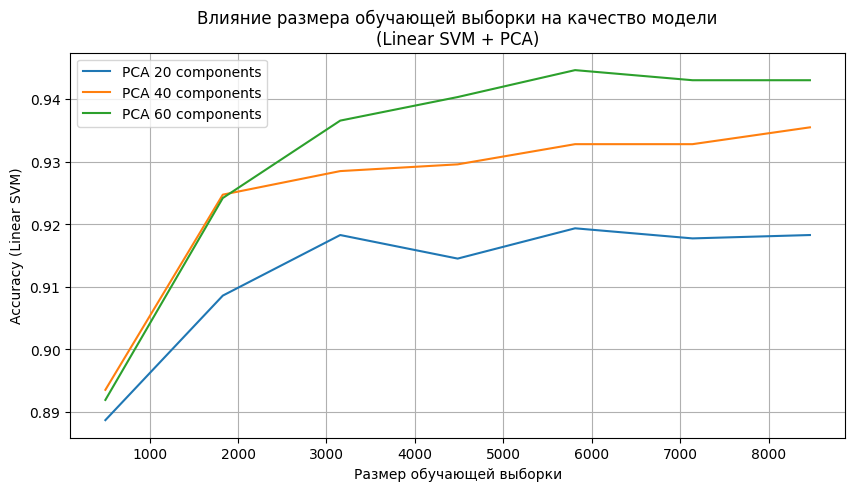

In [144]:
plt.figure(figsize=(10, 5))
for k in components:
    plt.plot(list(train_sizes), results_svm[k], label=f"PCA {k} components")

plt.xlabel("Размер обучающей выборки")
plt.ylabel("Accuracy (Linear SVM)")
plt.title("Влияние размера обучающей выборки на качество модели\n(Linear SVM + PCA)")
plt.grid(True)
plt.legend()
plt.show()
